# Page orientation: visual validation
## tl;dr
Run all cells to inspect corrections and per-page decisions. Errors and abstentions
are shown when present. The saved outputs use the actual CPU classifier, with no
mocked predictions.
**This is a deliberately small demonstration, not an estimate of production accuracy.**

With the three invented handwriting styles, the saved run correctly orients all 22
agreement, sparse-signature, and public-page examples, with no reviews at threshold 0.6.
The automatic-policy experiment covers 43 labeled demo pages: the raw model and
selective views get 43 correct; the combined policy gets 42, introducing a covered-text
error. These are synthetic/public challenge cases, with no held-out real PDFs;
keep the production policy unchanged.


## Context & Methods
Use `uv sync --locked --group notebook`, then `uv run --group notebook jupyter lab`.
Run from the repository root. Model weights download once; the two public example images are bundled.

### Key Assumptions
- Ground truth is the known **counterclockwise (CCW) rotation** of an upright reference.
  Expected model label = `(-CCW) % 360`; correction uses the predicted label CCW.
- One ONNX CPU session is reused. Previews honor PDF `/Rotate` and are rendered at up to
  125 DPI, capped at 1600 px before allocation. The classifier resizes the short edge to
  256 and takes its native **224 × 224 center crop**; headers and footers may be excluded.
  Saved PDFs retain original contents and resolution; accepted corrections change `/Rotate`.
- Threshold **0.6**: lower scores retain the displayed input. A review is not a successful
  automatic correction; an initially upright retained page can still be upright.
- Five timed passes visit all pages in seeded random order **after warm-up**. Reported
  inference milliseconds come from `orient_pdf.predict`: model preprocessing, execution,
  and postprocessing, excluding rasterization, input thumbnailing, plotting, and PDF writing.
- Repeated timings and rotated copies are correlated. Two public pages do not constitute
  an independent orientation benchmark. Sparse layouts were deliberately chosen to expose failure.

In [1]:
from pathlib import Path
from contextlib import redirect_stdout
from time import perf_counter
import hashlib, io, json, os, platform
import fitz
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
import orient_pdf as op
from test_orient import sample_pdf, font, draw_signature

ROOT = Path.cwd()
assert (ROOT / "orient_pdf.py").exists(), "Start Jupyter from the repository root"
DATA = ROOT / "validation_data"
DATA.mkdir(exist_ok=True)
THRESHOLD, REPEATS, INCLUDE_PUBLIC = 0.6, 5, True
plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})
print(f"Python {platform.python_version()} | {platform.machine()} | CPU count {os.cpu_count()}")
print(f"ONNX CPU threads: {os.getenv('ORIENT_THREADS', '2')} | threshold {THRESHOLD}")

Python 3.13.0 | x86_64 | CPU count 4
ONNX CPU threads: 2 | threshold 0.6


## Data
Three synthetic PDF documents: a six-page agreement with accents and Chinese names (if the
font exists), a four-page sparse signatory register, and a four-page footer-only signatory
layout. Three invented signature styles use connected letterforms, pen lifts, and
small variations in spacing and baseline. They are synthetic, not captured handwriting.
All documents include known rotations. The sparse pages have readable upright names, giving
human reviewers an orientation reference even when handwriting dominates.

Optionally add two [DocLayNet](https://github.com/DS4SD/DocLayNet) pages, each at all four
rotations. Their original text was visually checked upright. These are 1025 × 1025 images
as supplied by the [DocLayNet-small mirror](https://huggingface.co/datasets/pierreguillou/DocLayNet-small),
not original-resolution scans, and contain no signature evaluation. Set `INCLUDE_PUBLIC=False`
to exclude them. See [data provenance and license](data/doclaynet/README.md).

In [2]:
def sparse_page(footer_only=False):
    page = Image.new("RGB", (1000, 1400), "white")
    draw = ImageDraw.Draw(page)
    draw.text((65, 70), "SIGNATURES / SIGNATURES DES PARTIES", font=font(20), fill="black")
    for i, name in enumerate(["Élodie García", "François Müller", "Anaïs López"]):
        y = 1050 + i * 85 if footer_only else 240 + i * 340
        draw.text((65, y), name, font=font(16), fill="black")
        draw_signature(draw, (400, y + 42), i, seed=420 + i)
    return page


def write_rotations(path, upright):
    with fitz.open() as pdf:
        for ccw, flag in zip((0, 90, 180, 270), (0, 90, 0, 270)):
            scan = upright.rotate((ccw + flag) % 360, expand=True)
            data = io.BytesIO()
            scan.save(data, format="PNG")
            page = pdf.new_page(width=scan.width * 72 / 125, height=scan.height * 72 / 125)
            page.insert_image(page.rect, stream=data.getvalue())
            page.set_rotation(flag)
        pdf.save(path, deflate=True)


documents = []
references = sample_pdf(DATA / "agreement.pdf")
documents.append(("Agreement", "synthetic", DATA / "agreement.pdf",
                  [image for _, image in references], [0, 90, 180, 270, 180, 0][:len(references)]))
for name, footer in [("Sparse register", False), ("Footer signatures", True)]:
    upright = sparse_page(footer)
    path = DATA / ("footer.pdf" if footer else "sparse.pdf")
    write_rotations(path, upright)
    documents.append((name, "synthetic", path, [upright] * 4, [0, 90, 180, 270]))

if INCLUDE_PUBLIC:
    source_dir = ROOT / "data/doclaynet"
    manifest = json.loads((source_dir / "manifest.json").read_text())
    for entry in manifest:
        source = source_dir / entry["file"]
        assert hashlib.sha256(source.read_bytes()).hexdigest() == entry["sha256"]
        upright = Image.open(source).convert("RGB")
        name = f"DocLayNet row {entry['row_index']}"
        path = DATA / f"doclaynet-{entry['row_index']}.pdf"
        write_rotations(path, upright)
        documents.append((name, "public", path, [upright] * 4, [0, 90, 180, 270]))

display(pd.DataFrame([{"Document": n, "Source": s, "Pages": len(r), "PDF": p.name}
                      for n, s, p, r, a in documents]))

,Document,Source,Pages,PDF
0,Agreement,synthetic,6,agreement.pdf
1,Sparse register,synthetic,4,sparse.pdf
2,Footer signatures,synthetic,4,footer.pdf
3,DocLayNet row 0,public,4,doclaynet-0.pdf
4,DocLayNet row 1,public,4,doclaynet-1.pdf


### Load once; use the actual pipeline
`orient_pages` supplies the decisions. The comparison gallery renders the actual files
written by `orient_pdf`, which preserves original page contents. Timed repeat predictions
must agree with those decisions; no labels, confidence values, or failures are substituted.

In [3]:
started = perf_counter()
model = op.load_model()
load_ms = (perf_counter() - started) * 1000
with fitz.open(documents[0][2]) as pdf:
    warmup = op.rasterize(pdf[0])
for _ in range(3):
    op.predict(warmup, model)
print(f"Model setup: {load_ms:.0f} ms (excluded); three warm-up predictions excluded")

records, previews = [], {}
for name, source, path, originals, rotations in documents:
    with fitz.open(path) as pdf, redirect_stdout(io.StringIO()):
        for page_index, angle, confidence, corrected in op.orient_pages(pdf, model, THRESHOLD):
            key = len(records)
            ccw = rotations[page_index]
            accepted = confidence >= THRESHOLD
            residual = (ccw + (op.correction_angle(angle) if accepted else 0)) % 360
            records.append(dict(id=key, document=name, source=source, page=page_index,
                ccw=ccw, expected=(-ccw) % 360, predicted=angle, confidence=confidence,
                accepted=accepted, classifier_correct=angle == (-ccw) % 360,
                final_upright=residual == 0, residual=residual))
            previews[key] = (op.rasterize(pdf[page_index]), corrected, originals[page_index])
    output_path = path.with_name(path.stem + "-oriented.pdf")
    with redirect_stdout(io.StringIO()):
        op.orient_pdf(path, output_path, model, THRESHOLD)
    with fitz.open(output_path) as output:
        for key in [row["id"] for row in records if row["document"] == name]:
            before, _, reference = previews[key]
            previews[key] = (before, op.rasterize(output[records[key]["page"]]), reference)
results = pd.DataFrame(records)

# Seeded interleaving avoids always timing the same document first.
timings = []
rng = np.random.default_rng(42)
for repeat in range(REPEATS):
    for key in rng.permutation(len(results)):
        row = results.loc[key]
        angle, confidence, scores, ms = op.predict(previews[key][0], model)
        assert angle == row.predicted and abs(confidence - row.confidence) < 1e-4
        timings.append(dict(document=row.document, id=int(key), repeat=repeat, ms=ms))
        if repeat == 0:
            results.loc[key, "p0"] = scores[0]
            results.loc[key, "p180"] = scores[180]
timing = pd.DataFrame(timings)
results["wrong_auto"] = results.accepted & ~results.final_upright
results["review"] = ~results.accepted
results.to_csv(DATA / "page_results.csv", index=False)
timing.to_csv(DATA / "inference_timings.csv", index=False)
print(f"Measured {len(results)} pages across {len(documents)} documents; {len(timing)} timed calls")

2026-11-06 10:23:59.938123471 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full.0.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:23:59.938592305 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.6.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:23:59.938623413 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.3.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:23:59.938633623 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.0.0'. It is not used by any node and should be removed from the model.


Model setup: 46 ms (excluded); three warm-up predictions excluded


Measured 22 pages across 5 documents; 110 timed calls


## Results
### Accuracy and review workload by document
**Classifier accuracy** uses all pages, even abstentions. **Coverage** is the share accepted
for automatic correction. **Accepted accuracy** uses only accepted pages. **Final upright**
also counts unrotated, already-upright pages. **Wrong auto** counts incorrectly oriented
accepted outputs. Overall rates below are page-weighted, not averages of document rates.

,Pages,Classifier %,Coverage %,Accepted accuracy %,Final upright %,Reviews,Wrong auto
Agreement,6.0,100.0,100.0,100.0,100.0,0.0,0.0
Sparse register,4.0,100.0,100.0,100.0,100.0,0.0,0.0
Footer signatures,4.0,100.0,100.0,100.0,100.0,0.0,0.0
DocLayNet row 0,4.0,100.0,100.0,100.0,100.0,0.0,0.0
DocLayNet row 1,4.0,100.0,100.0,100.0,100.0,0.0,0.0
Overall,22.0,100.0,100.0,100.0,100.0,0.0,0.0


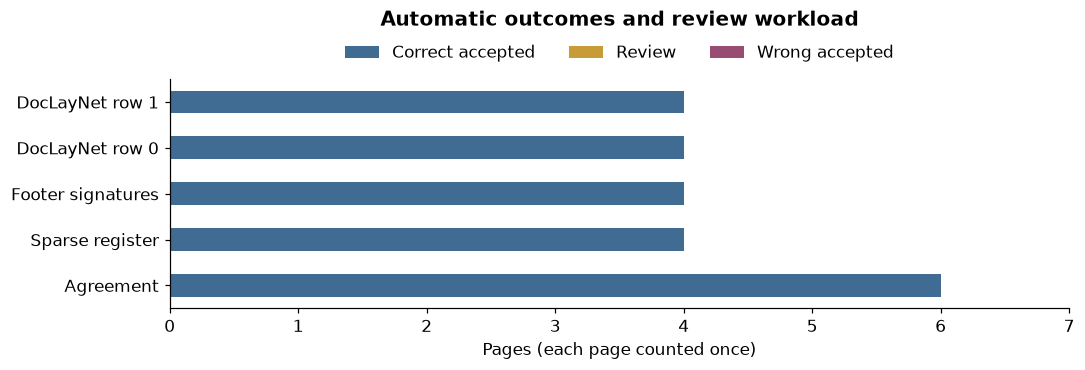

In [4]:
def summarize(frame):
    accepted = frame[frame.accepted]
    return pd.Series({"Pages": len(frame), "Classifier %": 100 * frame.classifier_correct.mean(),
        "Coverage %": 100 * frame.accepted.mean(),
        "Accepted accuracy %": 100 * accepted.final_upright.mean() if len(accepted) else np.nan,
        "Final upright %": 100 * frame.final_upright.mean(),
        "Reviews": int(frame.review.sum()), "Wrong auto": int(frame.wrong_auto.sum())})

summary = pd.DataFrame({name: summarize(group) for name, group in results.groupby("document", sort=False)}).T
summary.loc["Overall"] = summarize(results)
display(summary.round(1))
counts = pd.DataFrame({
    "Correct accepted": results.accepted & results.final_upright,
    "Review": results.review,
    "Wrong accepted": results.wrong_auto,
}).groupby(results.document, sort=False).sum()
ax = counts.plot.barh(stacked=True, figsize=(10, 3.5), color=["#406c94", "#c79b36", "#994c72"])
ax.set(xlabel="Pages (each page counted once)", ylabel="", title="Automatic outcomes and review workload")
ax.legend(loc="lower center", bbox_to_anchor=(.5, 1.01), ncol=3, frameon=False)
ax.set_title("Automatic outcomes and review workload", pad=35)
ax.set_xlim(0, counts.sum(axis=1).max() + 1)
plt.tight_layout()
plt.show()

### Confidence threshold and review workload
These are alternative decisions on the **same selected pages**, not independent experiments
or a production calibration set. Coverage uses all pages; accepted accuracy uses only pages
meeting the threshold. No accepted pages means accuracy is undefined, not 100%.
The current threshold remains 0.6. Zero observed errors in a small selected sample cannot
establish a near-100% production success rate.

,Threshold,Accepted,Reviews,Coverage %,Accepted accuracy %,Wrong auto
0,0.00,22,0,100.00,100.0,0
1,0.60,22,0,100.00,100.0,0
2,0.70,22,0,100.00,100.0,0
3,0.80,20,2,90.91,100.0,0
4,0.90,18,4,81.82,100.0,0
5,0.95,0,22,0.00,NaN,0
6,1.00,0,22,0.00,NaN,0


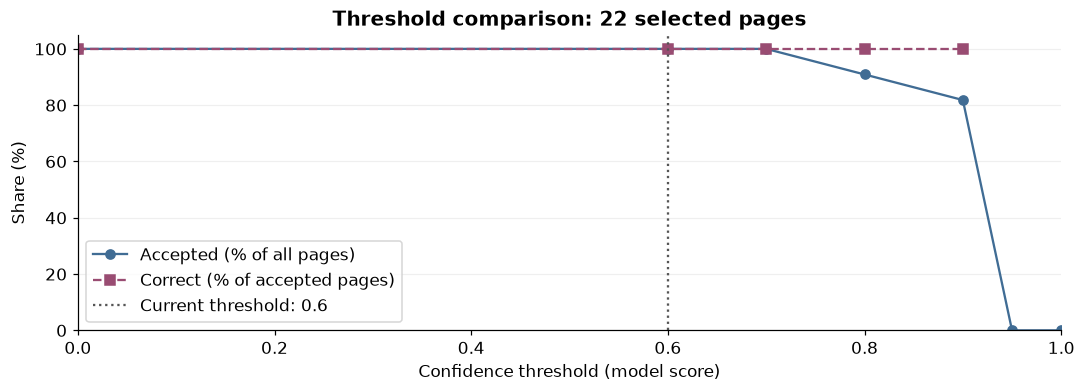

In [5]:
threshold_rows = []
for cutoff in sorted({0.0, THRESHOLD, 0.7, 0.8, 0.9, 0.95, 1.0}):
    accepted = results.confidence >= cutoff
    count = int(accepted.sum())
    wrong = int((accepted & ~results.classifier_correct).sum())
    threshold_rows.append({"Threshold": cutoff, "Accepted": count,
        "Reviews": len(results) - count, "Coverage %": 100 * count / len(results),
        "Accepted accuracy %": 100 * (count - wrong) / count if count else np.nan,
        "Wrong auto": wrong})
thresholds = pd.DataFrame(threshold_rows)
assert (thresholds.Accepted + thresholds.Reviews == len(results)).all()
default = thresholds.loc[thresholds.Threshold == THRESHOLD].iloc[0]
assert default["Reviews"] == int(results.review.sum())
assert default["Wrong auto"] == int(results.wrong_auto.sum())
assert np.isclose(default["Coverage %"], summary.loc["Overall", "Coverage %"])
thresholds.to_csv(DATA / "threshold_comparison.csv", index=False)
display(thresholds.round(2))
fig, ax = plt.subplots(figsize=(10, 3.7))
ax.plot(thresholds.Threshold, thresholds["Coverage %"], "o-", color="#406c94",
        label="Accepted (% of all pages)")
ax.plot(thresholds.Threshold, thresholds["Accepted accuracy %"], "s--", color="#994c72",
        label="Correct (% of accepted pages)")
ax.axvline(THRESHOLD, color="#555555", linestyle=":", label=f"Current threshold: {THRESHOLD}")
ax.set(xlabel="Confidence threshold (model score)", ylabel="Share (%)",
       xlim=(0, 1), ylim=(0, 105), title=f"Threshold comparison: {len(results)} selected pages")
ax.legend(loc="lower left")
ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

### Inference time statistics
Warm CPU prediction calls (model preprocessing and execution); each page is measured five times. P95 uses NumPy's linear
percentile interpolation. Standard deviation is the sample standard deviation. Timings
reflect this machine and this small repeated workload, not end-to-end service latency.

Boxes span the 25th–75th percentiles; the orange line is the median and the blue diamond
is the mean. Whiskers reach the most extreme observations within 1.5 box widths of each
quartile; circles mark observations beyond them. With few calls per document, tail values
are sensitive to CPU scheduling.

,Calls,Mean ms,Median ms,P95 ms,Std ms,Min ms,Max ms
DocLayNet row 0,20.0,9.08,9.18,11.21,1.93,5.62,12.29
Footer signatures,20.0,9.84,10.49,12.88,2.28,6.10,13.80
DocLayNet row 1,20.0,8.74,9.26,12.92,2.43,5.56,13.78
Sparse register,20.0,9.46,9.85,12.25,2.08,6.16,13.26
Agreement,30.0,9.84,10.15,12.98,2.71,6.14,19.56
Overall,110.0,9.43,9.70,12.86,2.34,5.56,19.56


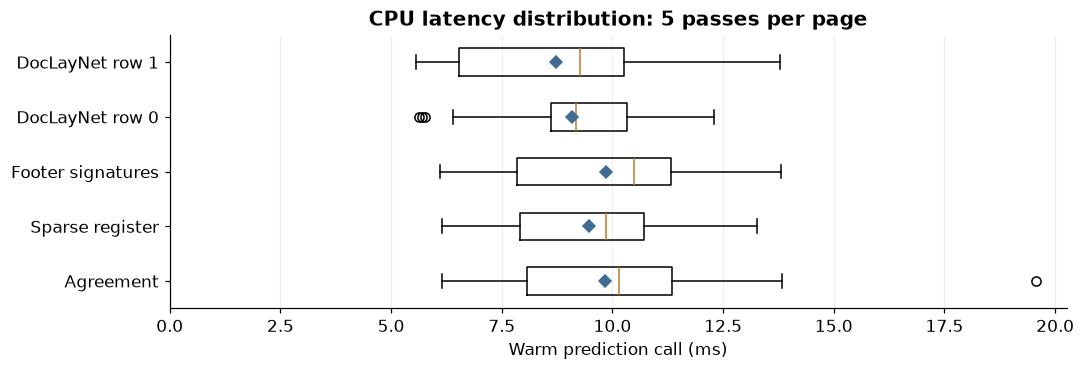

In [6]:
def latency_stats(frame):
    return pd.Series({"Calls": len(frame), "Mean ms": frame.ms.mean(), "Median ms": frame.ms.median(),
        "P95 ms": frame.ms.quantile(.95), "Std ms": frame.ms.std(ddof=1),
        "Min ms": frame.ms.min(), "Max ms": frame.ms.max()})
latencies = pd.DataFrame({name: latency_stats(group) for name, group in timing.groupby("document", sort=False)}).T
latencies.loc["Overall"] = latency_stats(timing)
display(latencies.round(2))
names = results.document.unique()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.boxplot([timing.loc[timing.document == name, "ms"] for name in names],
           orientation="horizontal", showmeans=True,
           medianprops={"color": "#bb7d26"},
           meanprops={"marker": "D", "markerfacecolor": "#406c94", "markeredgecolor": "#406c94"})
ax.set_yticks(range(1, len(names) + 1), labels=names)
ax.set(xlabel="Warm prediction call (ms)", title=f"CPU latency distribution: {REPEATS} passes per page")
ax.set_xlim(left=0)
ax.grid(axis="x", alpha=.2)
plt.tight_layout()
plt.show()

### Visual review: input → policy output → upright reference
Names and text in the reference establish the intended orientation. Titles show input CCW
rotation, predicted model label, confidence, and the **remaining CCW rotation** in the output.
The representative gallery includes rotations, mixed scripts when available, and a public
page. It also includes the first classification error and an abstention when present. Change `selected` or call `show_case(id)`
for any row in the page table below. Full pages are shown without text-region cropping.

For full-resolution input inspection, open the generated PDFs under `validation_data/`.
The `previews[id]` tuple retains bounded input/output previews and the reference image.
The notebook holds these images for plotting, so its RAM use is not a worker-memory benchmark.

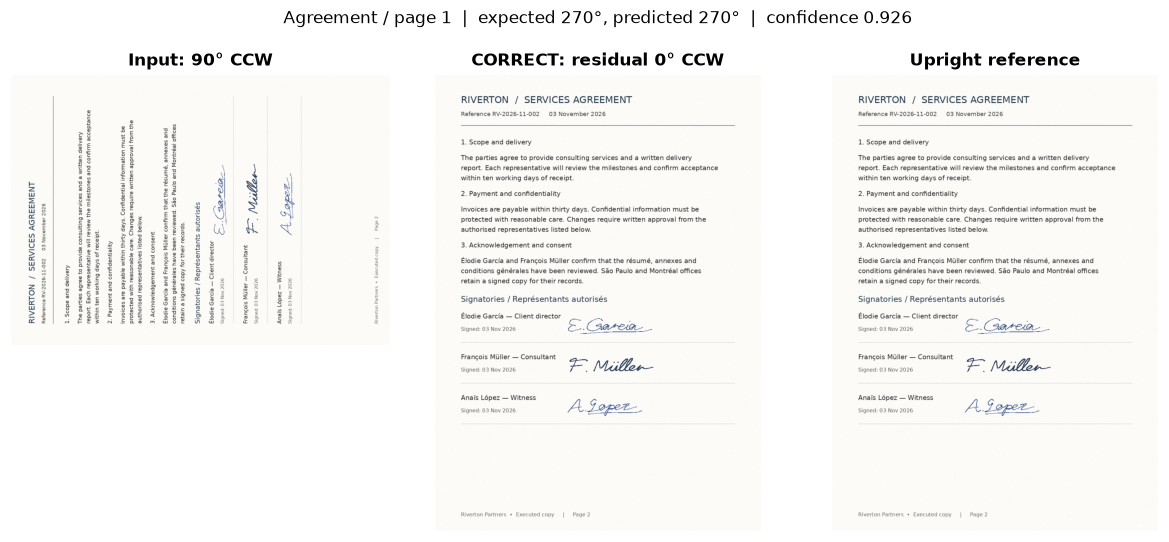

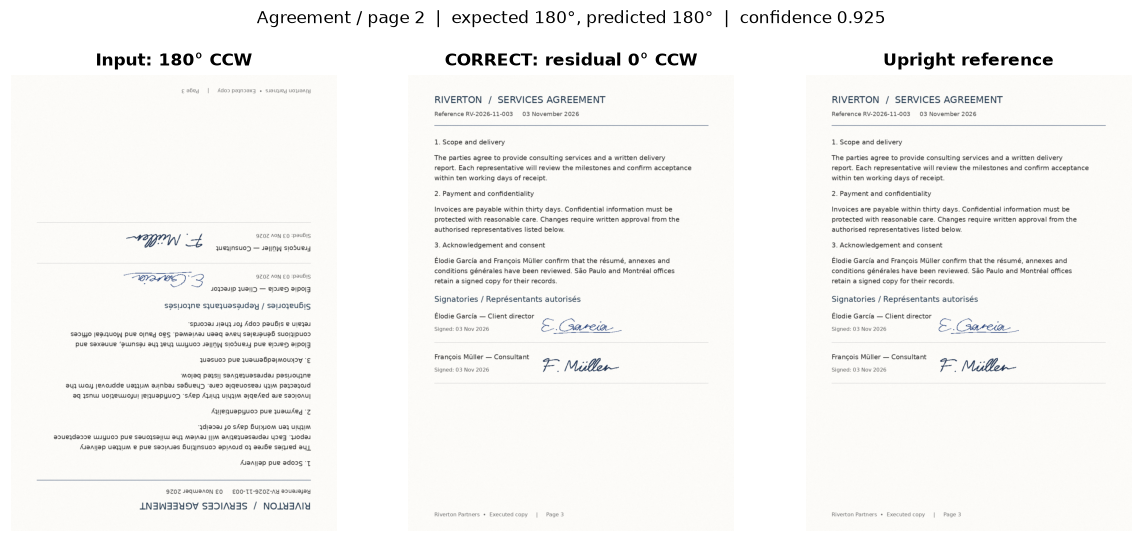

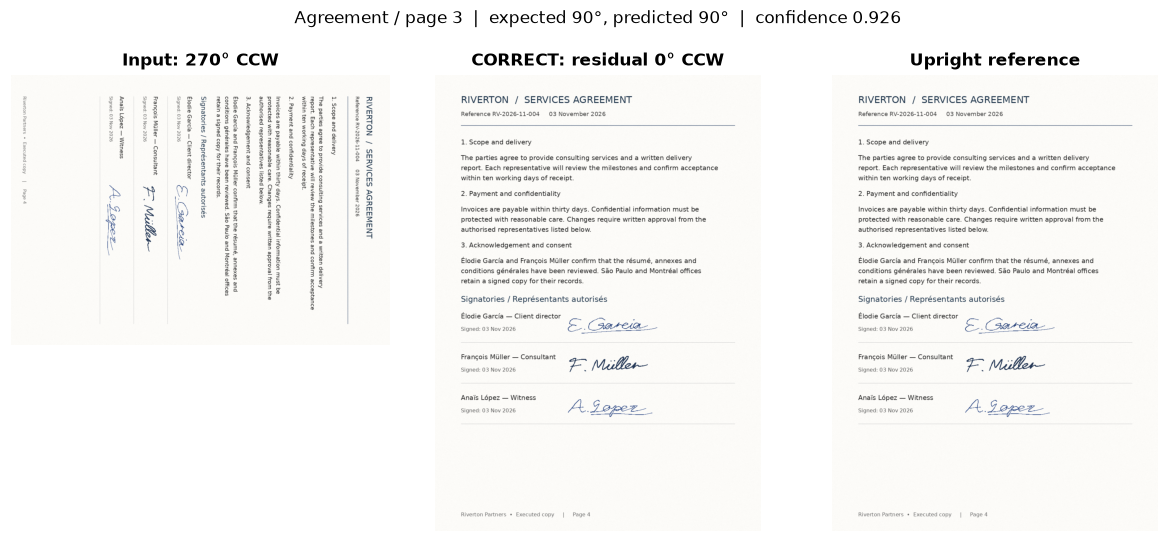

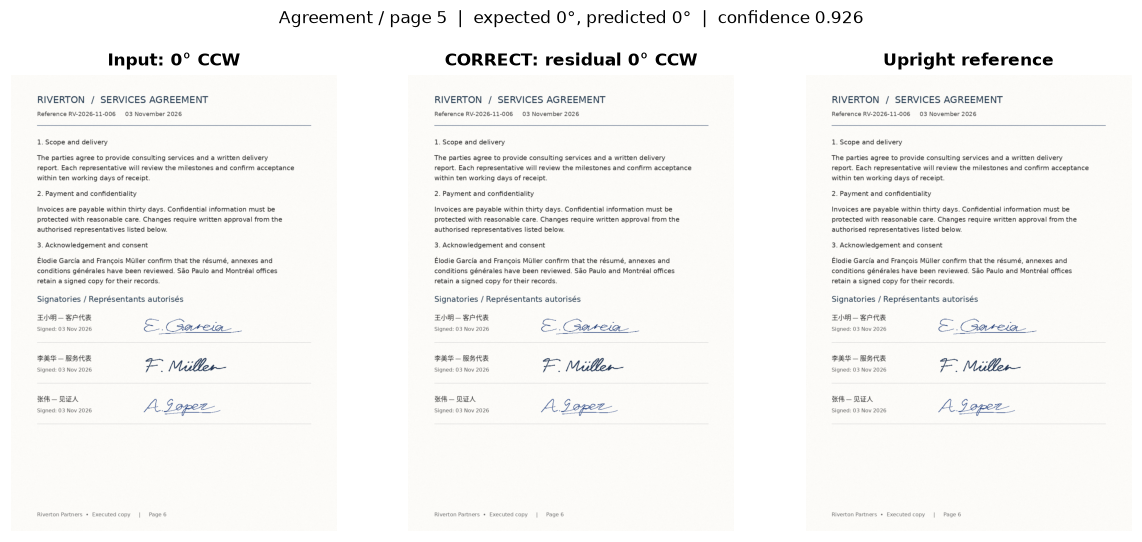

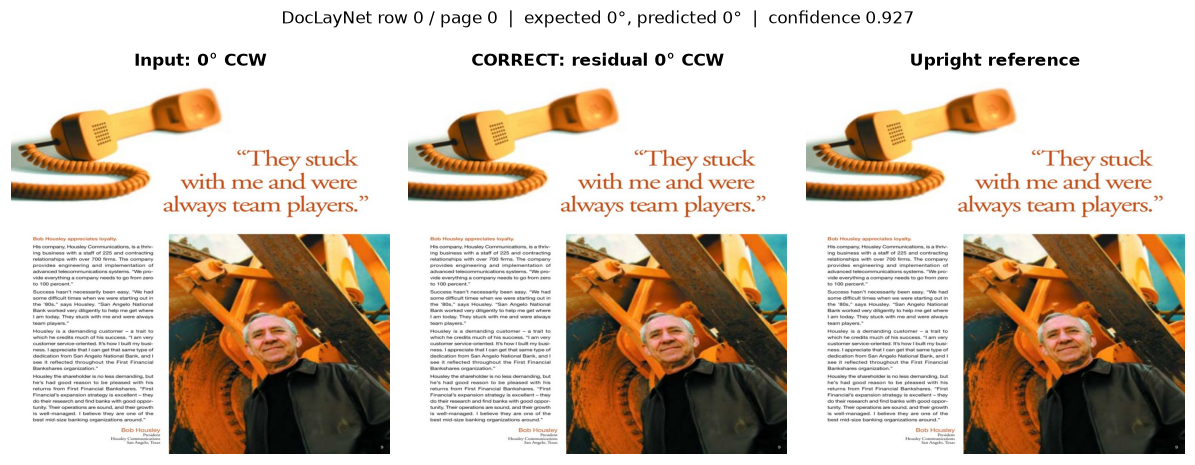

No confident error reproduced on this run. Review all sparse pages; do not fabricate a failure.

In [7]:
def show_case(key):
    row = results.loc[key]
    images = previews[key]
    state = "REVIEW" if row.review else ("CORRECT" if row.final_upright else "WRONG AUTO")
    fig, axes = plt.subplots(1, 3, figsize=(11, 5))
    titles = [f"Input: {row.ccw}° CCW", f"{state}: residual {row.residual}° CCW", "Upright reference"]
    for ax, image, title in zip(axes, images, titles):
        ax.imshow(image)
        ax.set_title(title, fontsize=11)
        ax.axis("off")
        ax.set_anchor("N")
    fig.suptitle(f"{row.document} / page {row.page}  |  expected {row.expected}°, predicted {row.predicted}°"
                 f"  |  confidence {row.confidence:.3f}", fontsize=11)
    plt.tight_layout()
    plt.show()

selected = results.index[(results.document == "Agreement") & results.ccw.isin([90, 180, 270])].tolist()[:3]
if len(references) == 6:
    selected.append(results.index[(results.document == "Agreement") & (results.page == 5)][0])
for mask in [results.wrong_auto, results.review & (results.ccw != 0), results.source == "public"]:
    candidates = results.index[mask]
    if len(candidates):
        selected.append(candidates[0])
for key in dict.fromkeys(selected):
    show_case(key)
if not results.wrong_auto.any():
    display(Markdown("No confident error reproduced on this run. Review all sparse pages; do not fabricate a failure."))

### Inspect every decision
Scores for both 0° and 180° help inspect reversal confusion. Confidence is a model softmax
score, not a calibrated probability that a page is correctly oriented. The failure condition
is measured against construction ground truth, independently of the model's confidence.

In [8]:
display(results[["id", "document", "page", "ccw", "expected", "predicted", "confidence",
                 "p0", "p180", "review", "wrong_auto", "final_upright"]].round(3))
assert int(summary.loc["Overall", "Pages"]) == len(results)
assert len(timing) == len(results) * REPEATS
assert (counts.sum(axis=1) == results.groupby("document", sort=False).size()).all()
assert np.isclose(summary.loc["Overall", "Final upright %"], 100 * results.final_upright.mean())
# A real error is displayed when present, never asserted as a model contract.
errors = results[~results.classifier_correct]
display(Markdown(f"**Observed:** {int(results.classifier_correct.sum())}/{len(results)} correct classifier labels; "
    f"{int(results.final_upright.sum())}/{len(results)} outputs upright; "
    f"{int(results.review.sum())} reviews; {int(results.wrong_auto.sum())} wrong automatic outputs. "
    f"Warm prediction median **{timing.ms.median():.1f} ms**, P95 **{timing.ms.quantile(.95):.1f} ms**."))
if len(errors):
    error = errors.iloc[0]
    display(Markdown(f"First classification failure: **{error.document}, page {error.page}**, "
        f"expected {error.expected}°, predicted {error.predicted}°, confidence {error.confidence:.3f}."))

,id,document,page,ccw,expected,predicted,confidence,p0,p180,review,wrong_auto,final_upright
0,0,Agreement,0,0,0,0,0.924,0.924,0.025,False,False,True
1,1,Agreement,1,90,270,270,0.926,0.024,0.024,False,False,True
2,2,Agreement,2,180,180,180,0.925,0.025,0.925,False,False,True
3,3,Agreement,3,270,90,90,0.926,0.025,0.025,False,False,True
4,4,Agreement,4,180,180,180,0.925,0.025,0.925,False,False,True
5,5,Agreement,5,0,0,0,0.926,0.926,0.024,False,False,True
6,6,Sparse register,0,0,0,0,0.923,0.923,0.025,False,False,True
7,7,Sparse register,1,90,270,270,0.926,0.024,0.025,False,False,True
8,8,Sparse register,2,180,180,180,0.926,0.025,0.926,False,False,True
9,9,Sparse register,3,270,90,90,0.925,0.025,0.024,False,False,True


**Observed:** 22/22 correct classifier labels; 22/22 outputs upright; 0 reviews; 0 wrong automatic outputs. Warm prediction median **9.7 ms**, P95 **12.9 ms**.

## Takeaways
- Inspect any wrong automatic outputs: the default confidence threshold cannot guarantee
  safety for signature-dominated pages. Sparse readable labels can disagree with the model.
- Review flags preserve input orientation; a rotated reviewed page remains rotated until
  a person corrects it. Final-upright rate alone hides this workload.
- Printed agreements and public report pages are useful controls, but not substitutes for
  a held-out collection of real scanned signatory documents. Do not tune a production
  threshold or claim a general accuracy rate from these selected cases.
- Public samples and their license/provenance are in `data/doclaynet/`. Generated PDFs,
  per-page decisions, and all timed calls are in ignored `validation_data/` for local audit.
  Rerun on the deployment CPU to measure its latency; PDF I/O and cold startup add cost.
- Compare thresholds only as a demonstration here. Before deployment, label real documents,
  split by original document **and template** before adding rotations, choose a threshold
  on the calibration split, and measure accepted accuracy and review rate on untouched
  test documents. Rotated copies are not independent evidence. The default remains 0.6.
- Profile the worker in a fresh process on short and long PDFs. Record cold setup, warm
  prediction time, complete PDF processing time, and peak resident RAM; memory still grows
  with the original document's objects even though previews are processed one at a time.

## Automatic policy experiment
The comparison below uses the experimental evaluator, independently timing four fully
automatic policies. The current threshold behavior above remains context. All cases here
are **demo** data: synthetic or bundled public pages, with no representative real test set.
Production adoption therefore remains pending regardless of demo accuracy.

The text/view settings are fixed in the evaluator before any inference. Text support,
model scores, and aggregate scores are different quantities, not probabilities of correctness.
Rendered text can be covered by later PDF objects; hidden OCR is excluded by visibility
flags. Additional views can repeat the original error. Native text and searchable scans
supplement the existing agreement, sparse-signature, footer-signature, and public controls.
An additional adversarial scan covers visible-marked, reversed OCR with an upright image.
Its known text-override failure is included in the accuracy totals and saved gallery.

In [9]:
import evaluate_orientation as ev
from test_evaluate_orientation import native_document

policy_entries = []
for name, source, path, originals, rotations in documents:
    policy_entries.append(dict(path=path.name, original_group=name, template_group=name,
        category=name, split="demo", expected=[(-r) % 360 for r in rotations],
        kind="public" if source == "public" else "synthetic",
        control="dense_printed" if source == "public" or name == "Agreement" else None))

# The same 16 combinations as the independent text-direction preservation tests.
native_rotations = [(ccw, flag) for ccw in ev.ANGLES for flag in ev.ANGLES]
native_path = DATA / "native-text.pdf"
native_document(native_path, native_rotations)
policy_entries.append(dict(path=native_path.name, original_group="native-original",
    template_group="native-template", category="Native text", split="demo",
    expected=[(flag - ccw) % 360 for ccw, flag in native_rotations],
    kind="synthetic", control="native_text"))

scan_rotations = [(ccw, flag) for ccw, flag in zip(ev.ANGLES, (0, 90, 0, 270))]
scan_path = DATA / "searchable-scan.pdf"
native_document(scan_path, scan_rotations, searchable_scan=True)
policy_entries.append(dict(path=scan_path.name, original_group="scan-original",
    template_group="native-template", category="Searchable scan", split="demo",
    expected=[(flag - ccw) % 360 for ccw, flag in scan_rotations], kind="synthetic"))
covered_path = DATA / "obscured-rendered-text.pdf"
native_document(covered_path, searchable_scan=True, obscured_text=True)
policy_entries.append(dict(path=covered_path.name, original_group="covered-original",
    template_group="native-template", category="Obscured rendered text", split="demo",
    expected=[0], kind="synthetic"))
blank_path = DATA / "blank.pdf"
with fitz.open() as pdf:
    pdf.new_page()
    pdf.save(blank_path)
policy_entries.append(dict(path=blank_path.name, original_group="blank-original",
    template_group="blank-template", category="Ambiguous blank", split="demo",
    expected=[None], kind="synthetic"))
policy_manifest = DATA / "orientation-demo-manifest.json"
policy_manifest.write_text(json.dumps(policy_entries, indent=2) + "\n")
policy_output = ev.evaluate(policy_manifest)
policy_summary = json.loads((policy_output / "summary.json").read_text())
policy_pages = pd.DataFrame(json.loads((policy_output / "pages.json").read_text()))
assert len(policy_pages) == sum(len(e["expected"]) for e in policy_entries) * 5
assert policy_summary["ambiguous_pages"] == 1
assert set(policy_pages.split) == {"demo"}
assert policy_summary["recommendation"]["status"] == "production_decision_pending"
print("Private evaluations stay local; this saved notebook runs only public/synthetic fixtures.")

Evaluating model: fresh worker, 5 corpus passes


2026-11-06 10:24:12.248548247 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full.0.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:24:12.248586843 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.6.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:24:12.248599286 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.3.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:24:12.248606386 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.0.0'. It is not used by any node and should be removed from the model.


Evaluating text: fresh worker, 5 corpus passes


2026-11-06 10:24:20.339877527 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full.0.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:24:20.339912044 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.6.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:24:20.339917358 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.3.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:24:20.339921813 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.0.0'. It is not used by any node and should be removed from the model.


Evaluating views: fresh worker, 5 corpus passes


2026-11-06 10:24:27.243124352 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full.0.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:24:27.243173635 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.6.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:24:27.243182286 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.3.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:24:27.243189708 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.0.0'. It is not used by any node and should be removed from the model.


Evaluating combined: fresh worker, 5 corpus passes


2026-11-06 10:24:39.802006448 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full.0.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:24:39.802056425 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.6.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:24:39.802065393 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.3.0'. It is not used by any node and should be removed from the model.
2026-11-06 10:24:39.802070779 [W:onnxruntime:, graph.cc:5777 CleanUnusedInitializersAndNodeArgs] Removing initializer 'p2o.pd_op.full_int_array.0.0'. It is not used by any node and should be removed from the model.


Results: /home/bsatom/Documents/document-image-orient/validation_data/orientation-6oimn01u


Combined/model median corpus time: 1.198x; production_decision_pending


Private evaluations stay local; this saved notebook runs only public/synthetic fixtures.


### Accuracy and changed decisions
Accuracy counts labeled pages equally. The blank page has no label and contributes only to
processing time. Counts of corrected and introduced errors compare each policy with the
raw model on the same pages. The threshold row applies the current 0.6 abstention rule;
the four experimental variants always make a decision.

,labeled,ambiguous,correct,accuracy,errors_180,errors_90_270,corrected_baseline_errors,introduced_errors
variant,,,,,,,,
model,43,1,43,1.000,0,0,0,0
text,43,1,42,0.977,1,0,0,1
views,43,1,43,1.000,0,0,0,0
combined,43,1,42,0.977,1,0,0,1
threshold_context,43,1,43,1.000,0,0,0,0


variant,combined,model,text,threshold_context,views
category,,,,,
Agreement,1.0,1.0,1.0,1.0,1.0
Ambiguous blank,NaN,NaN,NaN,NaN,NaN
DocLayNet row 0,1.0,1.0,1.0,1.0,1.0
DocLayNet row 1,1.0,1.0,1.0,1.0,1.0
Footer signatures,1.0,1.0,1.0,1.0,1.0
Native text,1.0,1.0,1.0,1.0,1.0
Obscured rendered text,0.0,1.0,0.0,1.0,1.0
Searchable scan,1.0,1.0,1.0,1.0,1.0
Sparse register,1.0,1.0,1.0,1.0,1.0


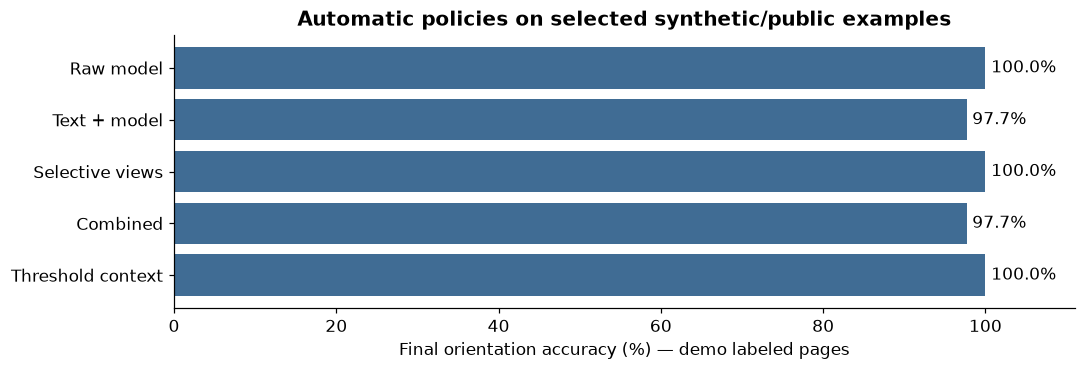

Combined corrects **0** baseline errors and introduces **1** new errors on **43** labeled demo pages. These selected examples do not establish held-out real-document accuracy.

In [10]:
policy_accuracy = pd.DataFrame(policy_summary["accuracy"])
policy_totals = policy_accuracy[policy_accuracy.category.isna()].set_index("variant").loc[
    [*ev.VARIANTS, "threshold_context"]]
display(policy_totals[["labeled", "ambiguous", "correct", "accuracy", "errors_180",
    "errors_90_270", "corrected_baseline_errors", "introduced_errors"]].round(3))
policy_categories = policy_accuracy[policy_accuracy.category.notna()]
display(policy_categories.pivot(index="category", columns="variant", values="accuracy").round(3))

# Independently reconcile rates, paired differences, and error counts with page decisions.
for variant, group in policy_pages.groupby("variant"):
    labeled = group[group.expected.notna()]
    correct = labeled.angle.eq(labeled.expected)
    residual = (labeled.angle - labeled.expected) % 360
    baseline_correct = labeled.baseline_angle.eq(labeled.expected)
    reported = policy_totals.loc[variant]
    assert reported.labeled == len(labeled) and reported.correct == int(correct.sum())
    assert np.isclose(reported.accuracy, correct.mean())
    assert reported.errors_180 == int(residual.eq(180).sum())
    assert reported.errors_90_270 == int(residual.isin([90, 270]).sum())
    assert reported.corrected_baseline_errors == int((~baseline_correct & correct).sum())
    assert reported.introduced_errors == int((baseline_correct & ~correct).sum())
fig, ax = plt.subplots(figsize=(10, 3.5))
labels = ["Raw model", "Text + model", "Selective views", "Combined", "Threshold context"]
values = 100 * policy_totals.accuracy.to_numpy()
ax.barh(labels, values, color="#406c94")
for i, value in enumerate(values):
    ax.text(value + .7, i, f"{value:.1f}%", va="center")
ax.set(xlim=(0, 111), xlabel="Final orientation accuracy (%) — demo labeled pages",
       title="Automatic policies on selected synthetic/public examples")
ax.invert_yaxis()
plt.tight_layout()
plt.show()
display(Markdown(f"Combined corrects **{policy_totals.loc['combined', 'corrected_baseline_errors']:.0f}** "
    f"baseline errors and introduces **{policy_totals.loc['combined', 'introduced_errors']:.0f}** new errors "
    f"on **{policy_totals.loc['combined', 'labeled']:.0f}** labeled demo pages. "
    "These selected examples do not establish held-out real-document accuracy."))

### Complete processing time and worker RAM
Each policy runs in a fresh process with one model session and warm-up, followed by five
complete corpus passes, saving every output PDF on every pass. Timings include extraction,
rendering, inference, and PDF saving. They exclude setup and warm-up, reported separately.
Document P95 pools all document/pass latencies with linear percentile interpolation.
The filesystem is warm; this is not a cold-disk benchmark. Peak RAM belongs to each worker,
not this image-retaining notebook. The 2× line is the acceptance limit, not a measured result.
Linux peak RAM uses the approximate current-executable `VmHWM`, excluding the notebook
parent's inherited pre-exec high-water mark. Other Unix measurements identify their
`getrusage` limitation in the saved summary.

,Median corpus ms,Document P50 ms,Document P95 ms,Cold setup ms,Warm-up ms,Peak process MiB,Time / baseline
model,1434.04,141.35,364.93,455.04,111.22,577.34,1.00
text,1168.53,130.36,372.22,486.29,98.31,575.22,0.81
views,2395.65,214.99,611.41,476.13,108.76,576.68,1.67
combined,1718.15,173.24,483.84,439.85,89.11,573.82,1.20


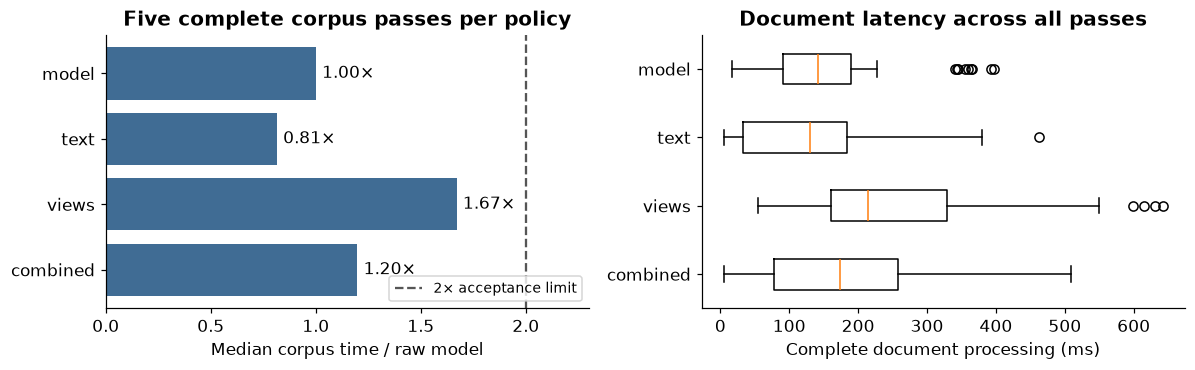

Combined median corpus time is **1.20×** raw model. The production decision is **pending**: representative real held-out PDFs are unavailable.

,Adoption gate passed
held_out_real_documents_available,False
held_out_real_accuracy_improved,False
labeled_test_controls_available,False
no_observed_control_regression,False
median_corpus_time_within_2x,True


In [11]:
policy_timing = pd.DataFrame({variant: {
    "Median corpus ms": data["median_corpus_ms"],
    "Document P50 ms": data["document_latency_ms"]["p50"],
    "Document P95 ms": data["document_latency_ms"]["p95"],
    "Cold setup ms": data["cold_setup_ms"], "Warm-up ms": data["warmup_ms"],
    "Peak process MiB": data["peak_process_ram_mib"]}
    for variant, data in policy_summary["timing"].items()}).T
policy_timing["Time / baseline"] = policy_timing["Median corpus ms"] / policy_timing.loc["model", "Median corpus ms"]
display(policy_timing.round(2))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
ratios = policy_timing["Time / baseline"].to_numpy()
axes[0].barh(list(ev.VARIANTS), ratios, color="#406c94")
axes[0].axvline(2, color="#555555", linestyle="--", label="2× acceptance limit")
for i, ratio in enumerate(ratios):
    axes[0].text(ratio + .03, i, f"{ratio:.2f}×", va="center")
axes[0].set(xlim=(0, max(2.3, max(ratios) * 1.2)), xlabel="Median corpus time / raw model",
            title="Five complete corpus passes per policy")
axes[0].invert_yaxis()
axes[0].legend(fontsize=9, loc="lower right")
axes[1].boxplot([[r["ms"] for r in policy_summary["timing"][v]["document_times"]]
                for v in ev.VARIANTS], orientation="horizontal", tick_labels=list(ev.VARIANTS))
axes[1].invert_yaxis()
axes[1].set(xlabel="Complete document processing (ms)", title="Document latency across all passes")
plt.tight_layout()
plt.show()
assert np.isclose(policy_summary["combined_time_ratio"], policy_timing.loc["combined", "Time / baseline"])
display(Markdown(f"Combined median corpus time is **{policy_summary['combined_time_ratio']:.2f}×** raw model. "
    "The production decision is **pending**: representative real held-out PDFs are unavailable."))
display(pd.Series(policy_summary["recommendation"]["gates"], name="Adoption gate passed").to_frame())

### Actual saved PDF comparisons
The input and all four outputs below are rendered from saved files, with a construction
reference derived from the known input correction. Selection includes a changed decision
when present, a remaining error when present, a rotated native-text page, and a searchable
scan. Use `show_policy_page(document_id, page_index)` to inspect any other case.
Text support and model/aggregate scores remain separately available in `pages.json`.

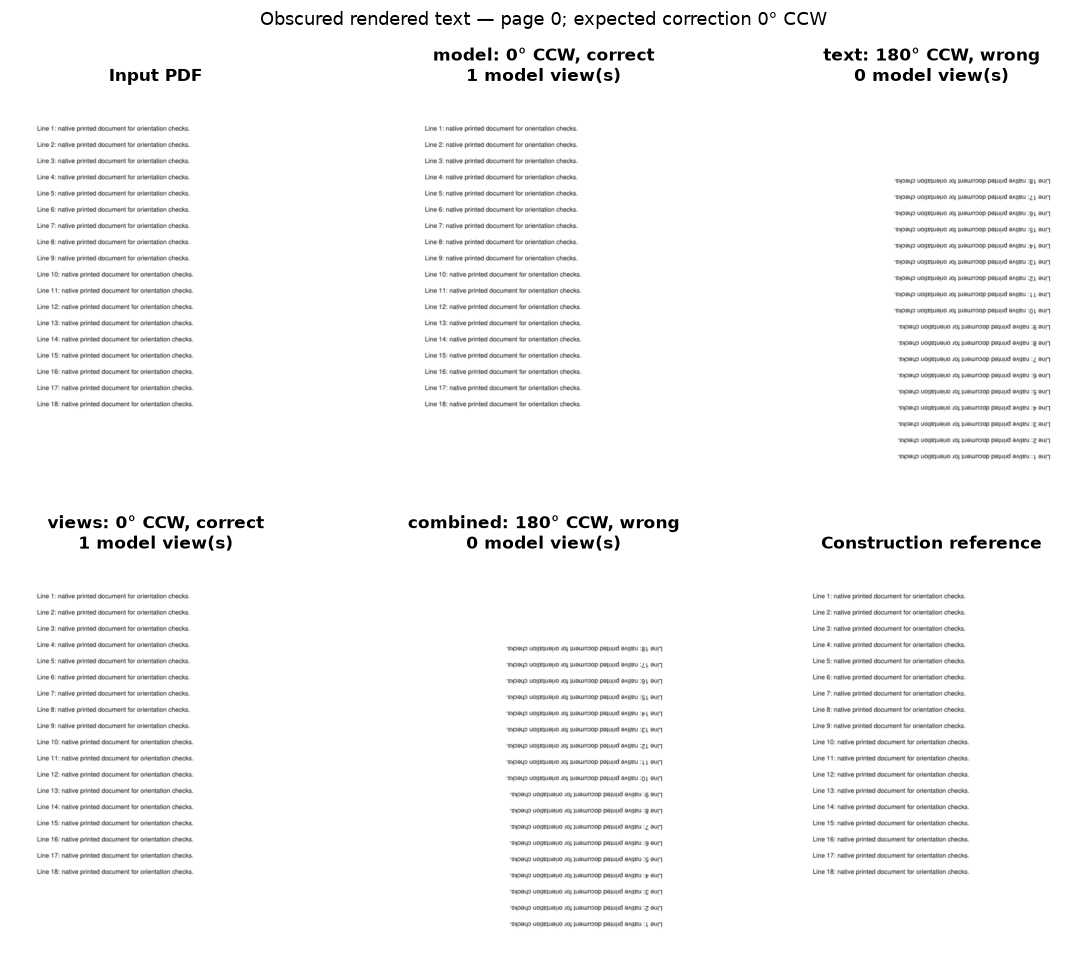

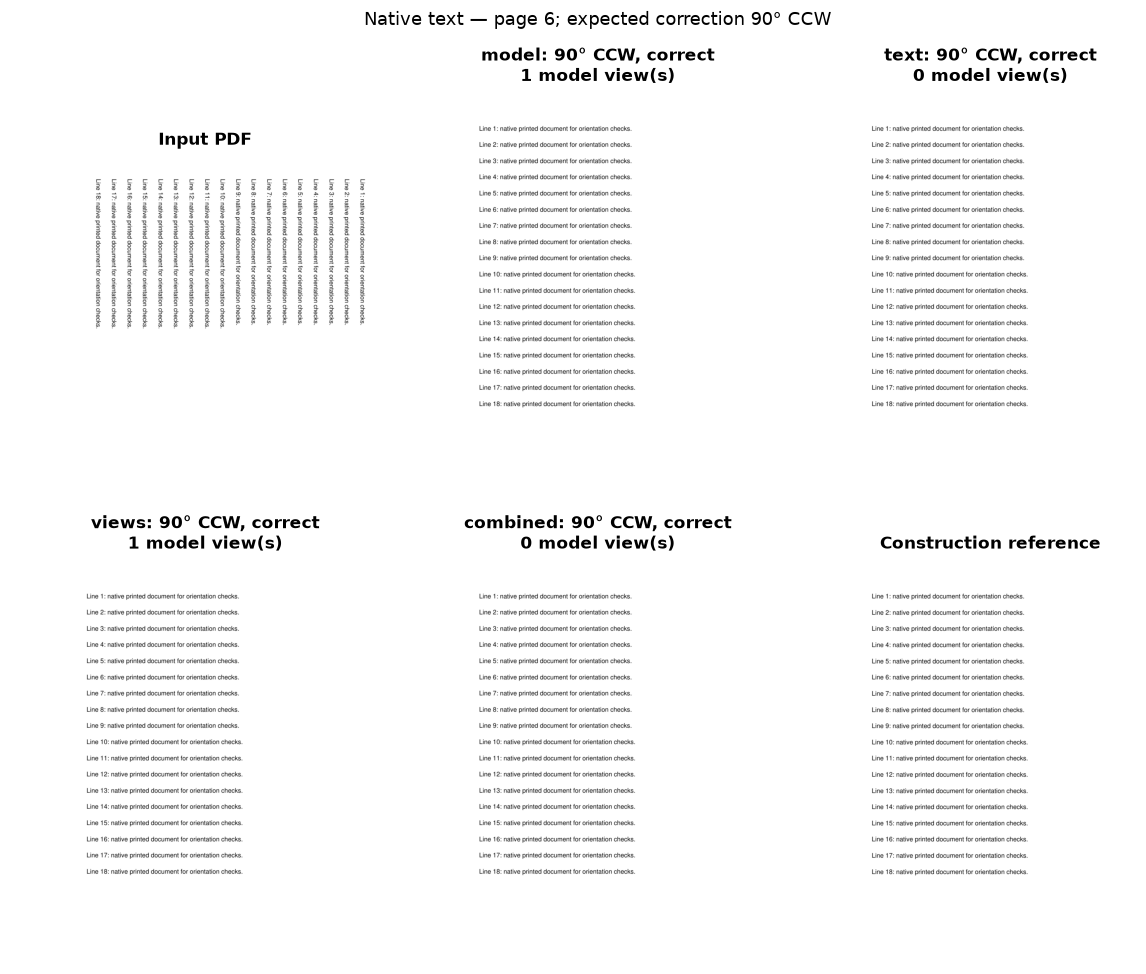

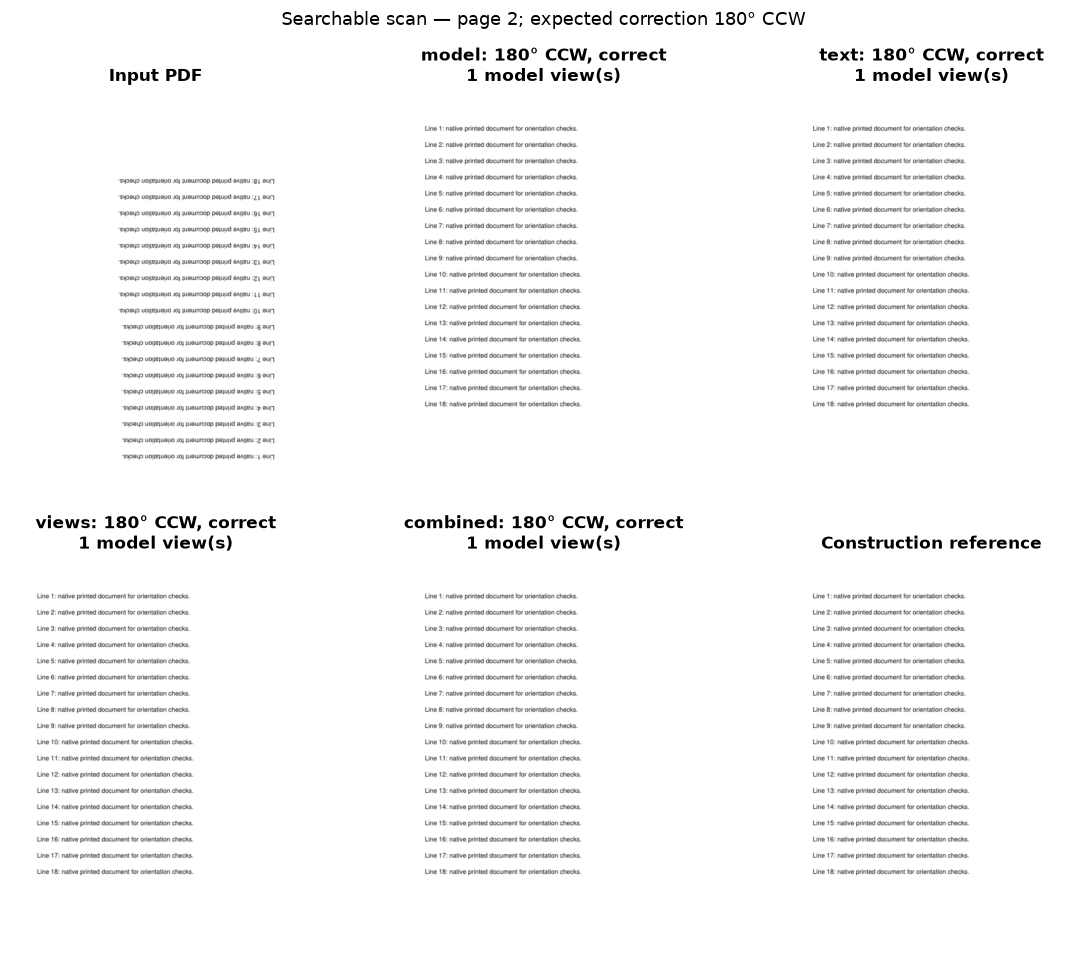

Pages
variant  Text reason                view_count       
combined no_visible_horizontal_text 1              25
                                    3               2
         qualifying_text            0              17
model    not requested              1              44
text     no_visible_horizontal_text 1              27
         qualifying_text            0              17
views    not requested              1              42
                                    3               2

All decisions, settings, per-pass timings, and corrected PDFs: /home/bsatom/Documents/document-image-orient/validation_data/orientation-6oimn01u


In [12]:
def show_policy_page(document_id, page_index):
    entry = policy_entries[document_id]
    with fitz.open(DATA / entry["path"]) as pdf:
        before = op.rasterize(pdf[page_index])
    images, titles = [before], ["Input PDF"]
    for variant in ev.VARIANTS:
        row = policy_pages[(policy_pages.document == document_id) &
                           (policy_pages.page == page_index) & (policy_pages.variant == variant)].iloc[0]
        with fitz.open(policy_output / row.output_pdf) as pdf:
            images.append(op.rasterize(pdf[page_index]))
        state = "ambiguous" if pd.isna(row.expected) else ("correct" if row.angle == row.expected else "wrong")
        titles.append(f"{variant}: {row.angle}° CCW, {state}\n{row.view_count} model view(s)")
    expected = entry["expected"][page_index]
    images.append(before.rotate(expected or 0, expand=True))
    titles.append("Construction reference" if expected is not None else "No orientation label")
    fig, axes = plt.subplots(2, 3, figsize=(11, 9))
    for ax, image, title in zip(axes.flat, images, titles):
        ax.imshow(image)
        ax.set_title(title, fontsize=11)
        ax.axis("off")
    fig.suptitle(f"{entry['category']} — page {page_index}; expected correction {expected}° CCW", fontsize=12)
    plt.tight_layout()
    plt.show()

combined_rows = policy_pages[policy_pages.variant == "combined"]
selected_policy = []
for mask in [combined_rows.angle.ne(combined_rows.baseline_angle),
             combined_rows.expected.notna() & combined_rows.angle.ne(combined_rows.expected)]:
    candidates = combined_rows[mask]
    if len(candidates):
        r = candidates.iloc[0]
        selected_policy.append((int(r.document), int(r.page)))
selected_policy.extend([(len(documents), 6), (len(documents) + 1, 2), (len(documents) + 2, 0)])
for key in dict.fromkeys(selected_policy):
    show_policy_page(*key)

policy_details = policy_pages[policy_pages.variant.isin(ev.VARIANTS)].copy()
policy_details["Text reason"] = policy_details.text.map(lambda t: t["reason"] if isinstance(t, dict) else "not requested")
display(policy_details.groupby(["variant", "Text reason", "view_count"], dropna=False).size().rename("Pages").to_frame())
print(f"All decisions, settings, per-pass timings, and corrected PDFs: {policy_output}")

### Decision
Keep the production CLI unchanged. On the 43 labeled demo pages, the raw model and
selective views each get 43 correct. The combined policy gets 42: its text shortcut
introduces a reversal on the covered, rendered OCR challenge. The more legible synthetic
signatures remove the sparse-page errors seen with the previous scribble generator;
this changes the fixtures, not the model or its preprocessing.

These selected successes cannot justify adoption. Before an adoption decision, label
representative real PDFs, keep originals/derivatives/templates together across splits,
fix settings on calibration data, and run the untouched policy on held-out test data.
Adoption requires improved real test accuracy, no observed newly introduced errors on
native-text or dense printed controls, and combined median corpus time at most 2× baseline.
A small number of observed successes cannot establish universal automatic orientation.
Private PDF results stay in ignored `validation_data/`, outside this saved notebook.
